In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
#### INPUT PATH
INPUT_PATH = 'alex\\force_dist_v2\\force-analysis'
path_k10r28 = os.path.join(INPUT_PATH, 'force_mag_K_10_r0_28.dat')
path_k10r24 = os.path.join(INPUT_PATH, 'force_mag_K_10_r0_24.dat')
path_k10r20 = os.path.join(INPUT_PATH, 'force_mag_K_10_r0_20.dat')
path_k10r16 = os.path.join(INPUT_PATH, 'force_mag_K_10_r0_16.dat')
path_k10r12 = os.path.join(INPUT_PATH, 'force_mag_K_10_r0_12.dat')
path_k10r08 = os.path.join(INPUT_PATH, 'force_mag_K_10_r0_08.dat')

In [3]:
data_k10r28 = pd.read_csv(path_k10r28, 
                          delim_whitespace=True, 
                          header=None,
                          names=['step', 'force_mag'])
data_k10r24 = pd.read_csv(path_k10r24, 
                          delim_whitespace=True, 
                          header=None,
                          names=['step', 'force_mag'])
data_k10r20 = pd.read_csv(path_k10r20, 
                          delim_whitespace=True, 
                          header=None,
                          names=['step', 'force_mag'])
data_k10r16 = pd.read_csv(path_k10r16, 
                          delim_whitespace=True, 
                          header=None,
                          names=['step', 'force_mag'])
data_k10r12 = pd.read_csv(path_k10r12, 
                          delim_whitespace=True, 
                          header=None,
                          names=['step', 'force_mag'])
data_k10r08 = pd.read_csv(path_k10r08, 
                          delim_whitespace=True, 
                          header=None,
                          names=['step', 'force_mag'])

C:\Users\Tristan\AppData\Local\Temp\ipykernel_40152\3627396248.py:1: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data_k10r28 = pd.read_csv(path_k10r28,
C:\Users\Tristan\AppData\Local\Temp\ipykernel_40152\3627396248.py:5: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data_k10r24 = pd.read_csv(path_k10r24,
C:\Users\Tristan\AppData\Local\Temp\ipykernel_40152\3627396248.py:9: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data_k10r20 = pd.read_csv(path_k10r20,
C:\Users\Tristan\AppData\Local\Temp\ipykernel_40152\3627396248.py:13: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  data_k10r16 = pd.read_csv(path

In [ ]:
from functions import moving_average_filter
# Apply MAF with tuneable window size (adjust as needed)
WINDOW_SIZE = 50  # Adjust this value to control smoothing

# Using the updated function with explicit parameters
data_k10r28_filtered = moving_average_filter(data_k10r28, window_size=WINDOW_SIZE, epoch_col='step', filter_cols='force_mag')
data_k10r24_filtered = moving_average_filter(data_k10r24, window_size=WINDOW_SIZE, epoch_col='step', filter_cols='force_mag')
data_k10r20_filtered = moving_average_filter(data_k10r20, window_size=WINDOW_SIZE, epoch_col='step', filter_cols='force_mag')
data_k10r16_filtered = moving_average_filter(data_k10r16, window_size=WINDOW_SIZE, epoch_col='step', filter_cols='force_mag')
data_k10r12_filtered = moving_average_filter(data_k10r12, window_size=WINDOW_SIZE, epoch_col='step', filter_cols='force_mag')
data_k10r08_filtered = moving_average_filter(data_k10r08, window_size=WINDOW_SIZE, epoch_col='step', filter_cols='force_mag')

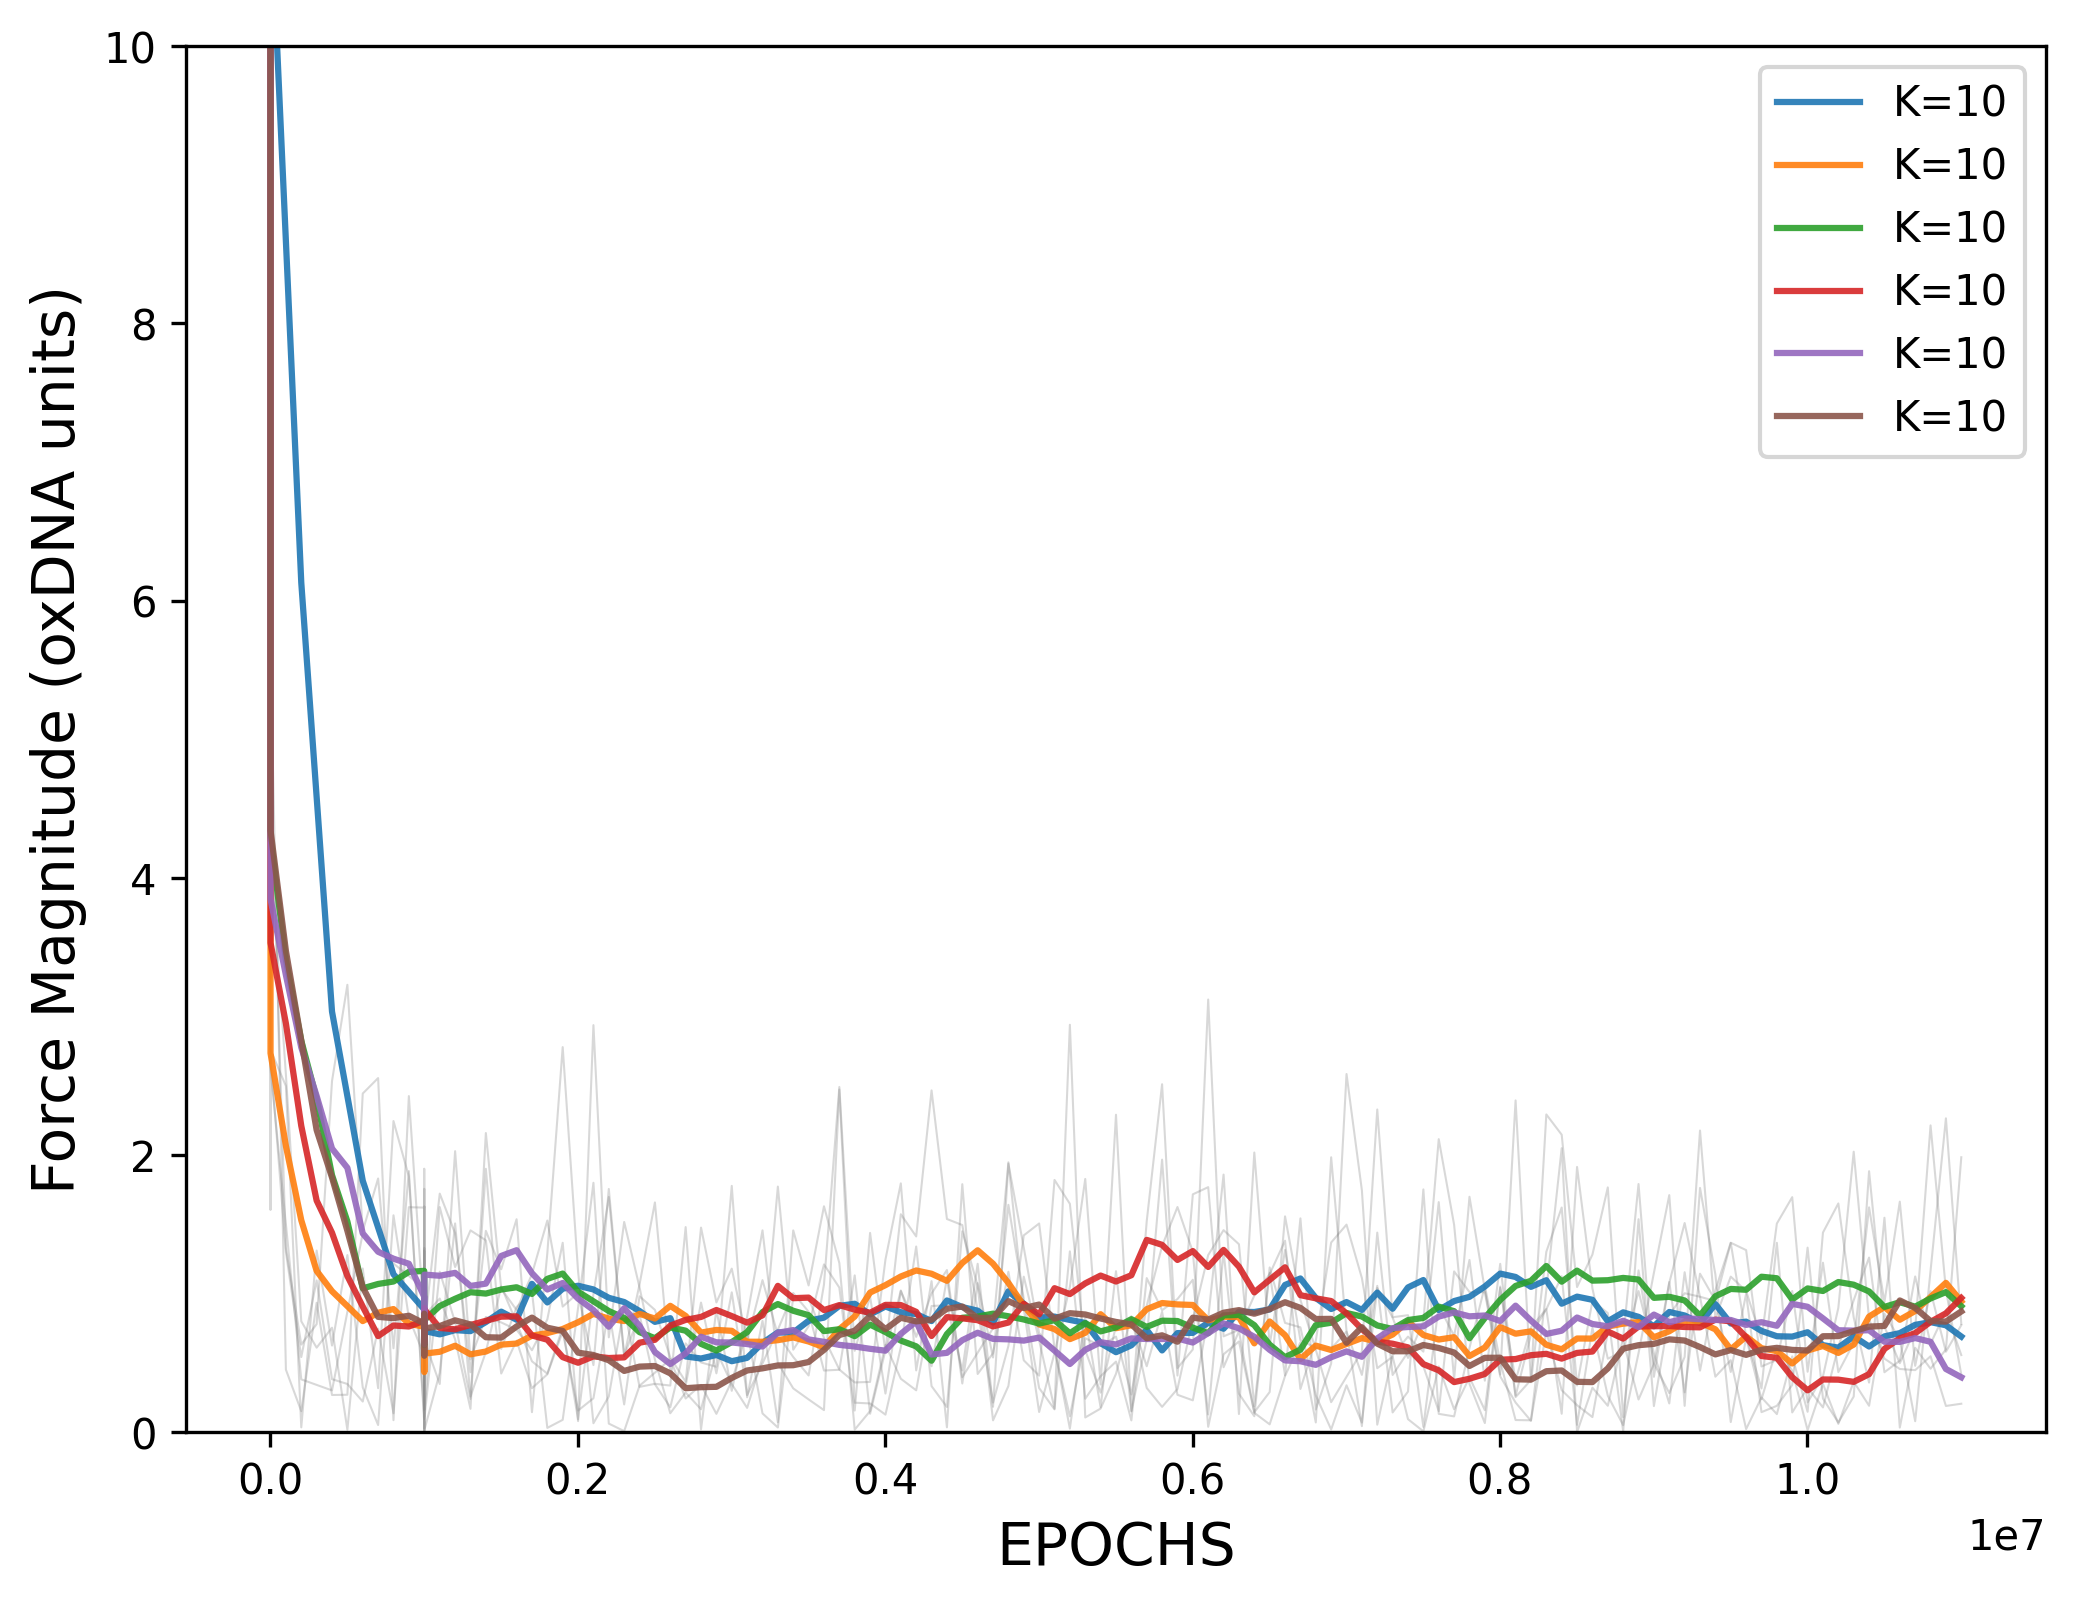

In [5]:
fig, ax = plt.subplots(figsize=(8,6), dpi=300)

# Plot original signals
for set in [data_k10r28, data_k10r24, data_k10r20, data_k10r16, data_k10r12, data_k10r08]:
    ax.plot(set['step'], set['force_mag'], alpha=0.3, linewidth=0.5, color='gray')

# Plot filtered signals
for set in [data_k10r28_filtered, data_k10r24_filtered, data_k10r20_filtered, 
            data_k10r16_filtered, data_k10r12_filtered, data_k10r08_filtered]:
    ax.plot(set['step'], 
            set['force_mag_filtered'], 
            alpha=0.9, 
            linewidth=1.5,
            label=f"K=10")

ax.set_xlabel('EPOCHS', fontsize=14)
ax.set_ylabel('Force Magnitude (oxDNA units)', fontsize=14)
ax.set_ylim(0, 10)
ax.legend()